# Stefan problem: Stefan condition method

Forward Euler for the front position $s$ from the Stefan condition, Backward Euler for the finite element coefficients $W$. The integral form method is in `Stefan_notebook.ipynb`; both notebooks use `params.py` and `functions.py`.

In [1]:
import os
import numpy as np
from scipy.linalg import solve_banded
import matplotlib.pyplot as plt

from params import m_L, a_L, mu, T
from functions import assemble, lam, s_exact, m_exact, u_exact, l2_error, eoc, eoc_table

os.makedirs("figures", exist_ok=True)   # all plots are saved here
os.makedirs("tables", exist_ok=True)    # LaTeX tables, \input{tables/...} in the report

## Parameters

In [2]:
# Material data (SI units) and final time T: see params.py

Nt = 100      # number of time steps
Ny = 40       # number of elements on [0, 1]
r  = 2        # grading of the time mesh, r = 1 gives a uniform mesh

def graded_times(T, Nt, r=2):
    return T * (np.arange(Nt + 1) / Nt)**r     # t_n = T (n / Nt)^r

## Time stepping

For $s_0 = 0$ the update $\dot s = q/s$ would divide by $s(0) = 0$, so the scheme starts at $t_1$ from the Neumann solution. The tridiagonal systems are solved with `solve_banded`, about ten times faster than `spsolve`, which matters for the $2^{17}$ time steps used below.

In [3]:
def banded(A):
    # tridiagonal sparse matrix -> (3, n) array for solve_banded
    ab = np.zeros((3, A.shape[0]))
    ab[0, 1:], ab[1], ab[2, :-1] = A.diagonal(1), A.diagonal(0), A.diagonal(-1)
    return ab

def solve_stefan(t, y, s0=0, history=False):
    M, K, C, b = assemble(y)
    Mb, Kb, Cb = banded(M), banded(K), banded(C)
    g = m_L * (1 - y)                    # lifting of the boundary values
    h = y[-1] - y[-2]                    # last element: w_y(1) = -W_{N-1} / h
    s = np.zeros(len(t))
    if s0 > 0:
        n0, s[0] = 0, s0
        W = -g[1:-1]                     # initial data m(x, 0) = 0
    else:
        n0, s[1] = 1, s_exact(t[1])      # start at t_1 from the Neumann solution
        W = u_exact(y[1:-1]) - g[1:-1]
    if history:
        m_all = np.zeros((len(t), len(y)))   # nodal temperatures at all time levels, m = 0 at t = 0
        m_all[n0] = np.r_[0, W, 0] + g

    for n in range(n0 + 1, len(t)):
        dt = t[n] - t[n - 1]
        q = a_L / mu * (m_L + W[-1] / h)            # q = s sdot at t_{n-1}, Stefan condition
        s[n] = s[n - 1] + dt * q / s[n - 1]         # Forward Euler for s
        A = s[n - 1]**2 * Mb + dt * (a_L * Kb - q * Cb)
        rhs = s[n - 1]**2 * (M @ W) - dt * m_L * q * b
        W = solve_banded((1, 1), A, rhs)            # Backward Euler for W
        if history:
            m_all[n] = np.r_[0, W, 0] + g

    m = m_all if history else np.r_[0, W, 0] + g    # nodal temperatures at all t (history) or at t[-1]
    return s, s[-1] * y, m               # s at all time levels, nodes x = y s at t[-1] and temperatures

def error_at_T(Nt, Ny, r=2):
    t = graded_times(T, Nt, r)
    y = np.linspace(0.0, 1.0, Ny + 1)
    s_h, x_h, m_h = solve_stefan(t, y)
    s_err = abs(s_h[-1] - s_exact(T))    # front position error at T
    m_err = l2_error(x_h, m_h, T)        # L2 error of the temperature at T
    return s_err, m_err

## Uniform vs graded time mesh ($s_0 = 0$)

Front position error $e_s(t_n) = |s_h(t_n) - s(t_n)|$ over the time levels, on a uniform ($r = 1$) and a graded ($r = 2$) time mesh with $N_t = 200$, $N_y = 5000$. The scheme starts from the Neumann solution at $t_1$, so $e_s(t_1) = 0$.

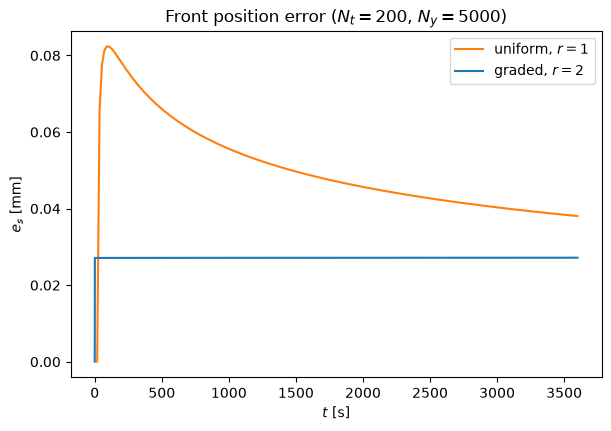

In [4]:
# Front position error over time on a uniform (r = 1) and a graded (r = 2) time mesh
Nt_cmp = 200
Ny_cmp = 5000
y_cmp = np.linspace(0.0, 1.0, Ny_cmp + 1)

fig, ax = plt.subplots(figsize=(6, 4.2), layout="constrained")
for rr, style, name in ((1, "C1-", "uniform"), (2, "C0-", "graded")):
    t_cmp = graded_times(T, Nt_cmp, rr)
    s_cmp, _, _ = solve_stefan(t_cmp, y_cmp)
    e_s = abs(s_cmp - s_exact(t_cmp))
    ax.plot(t_cmp[1:], 1e3 * e_s[1:], style, label=f"{name}, $r = {rr}$")   # no front at t_0 = 0
ax.set(xlabel="$t$ [s]", ylabel="$e_s$ [mm]",
       title=f"Front position error ($N_t = {Nt_cmp}$, $N_y = {Ny_cmp}$)")
ax.legend()
fig.savefig("figures/uniform_vs_graded_fe.pdf")
plt.show()

## Correctness on the graded mesh

Front position against the Neumann solution, and the temperature in the $(t, x)$ plane: the FEM solution $m_h(x, t)$ on the moving mesh $x = s_h(t)\,y$ next to the analytical $m(x, t)$, on the same colour scale. Right of the front the material is solid, $m = 0$.

lambda = 0.246225
s_h(T) = 10.90653 mm,  s(T) = 10.84442 mm,  rel. error = 5.73e-03
L2 error of m at T = 3.375e-03


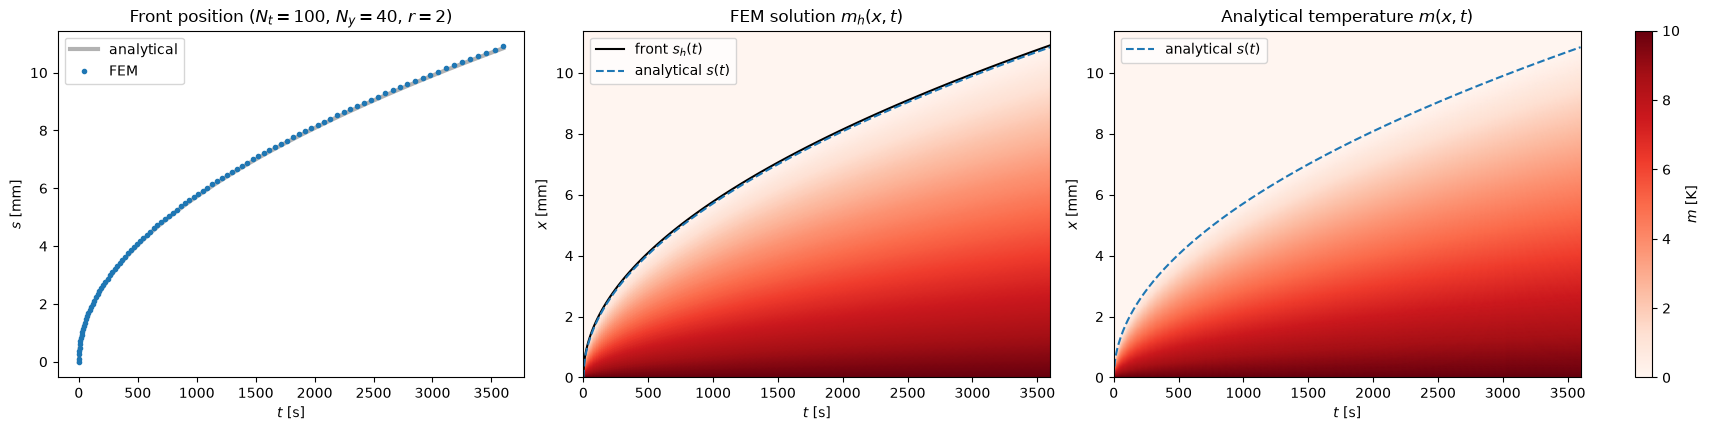

In [5]:
t = graded_times(T, Nt, r)
y = np.linspace(0.0, 1.0, Ny + 1)
s_h, x_h, m_hist = solve_stefan(t, y, history=True)
t_fine = np.linspace(0, T, 400)
print(f"lambda = {lam:.6f}")
print(f"s_h(T) = {s_h[-1]*1e3:.5f} mm,  s(T) = {s_exact(T)*1e3:.5f} mm,  "
      f"rel. error = {abs(s_h[-1] - s_exact(T)) / s_exact(T):.2e}")
print(f"L2 error of m at T = {l2_error(x_h, m_hist[-1], T):.3e}")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.2), layout="constrained")
ax1.plot(t_fine, 1e3 * s_exact(t_fine), "k-", lw=3, alpha=0.3, label="analytical")
ax1.plot(t, 1e3 * s_h, "C0.", label="FEM")
ax1.set(xlabel="$t$ [s]", ylabel="$s$ [mm]", title=f"Front position ($N_t = {Nt}$, $N_y = {Ny}$, $r = {r}$)")
ax1.legend()

x_max = 1.05 * s_exact(T)                # extra column of solid (m = 0) up to x_max
X = 1e3 * np.c_[s_h[:, None] * y, np.full(len(t), x_max)]
Tg = np.broadcast_to(t[:, None], X.shape)
heat = dict(cmap="Reds", shading="gouraud", vmin=0, vmax=m_L)
pc = ax2.pcolormesh(Tg, X, np.c_[m_hist, np.zeros(len(t))], **heat)
ax2.plot(t, 1e3 * s_h, "k-", lw=1.5, label="front $s_h(t)$")
ax2.plot(t_fine, 1e3 * s_exact(t_fine), "C0--", lw=1.5, label="analytical $s(t)$")
ax2.set(title="FEM solution $m_h(x, t)$")

t_ex, x_ex = np.meshgrid(t_fine[1:], np.linspace(0, x_max, 300), indexing="ij")   # t > 0, s(0) = 0
ax3.pcolormesh(t_ex, 1e3 * x_ex, m_exact(x_ex, t_ex), **heat)
ax3.plot(t_fine, 1e3 * s_exact(t_fine), "C0--", lw=1.5, label="analytical $s(t)$")
ax3.set(title="Analytical temperature $m(x, t)$")

for ax in (ax2, ax3):
    ax.set(xlabel="$t$ [s]", ylabel="$x$ [mm]", xlim=(0, T), ylim=(0, 1e3 * x_max))
    ax.legend(loc="upper left")
fig.colorbar(pc, ax=[ax2, ax3], label="$m$ [K]")
fig.savefig("figures/correctness_fe.pdf")
plt.show()

## Spatial order of convergence

Errors at $T$ against the Neumann solution on the graded mesh ($r = 2$). The time error is $s(T)/(2N_t)$, so a very fine time grid is needed to isolate the spatial error. This cell takes about half a minute.

In [6]:
Nt_fine = 2**17
Ny_list = 10 * 2**np.arange(7)           # 10, 20, ..., 640
err_space = np.array([error_at_T(Nt_fine, ny) for ny in Ny_list])
eoc_table("tables/eoc_space_fe.tex", "N_y", Ny_list, err_space[:, 0], err_space[:, 1])

     N_y          e_s     EOC          e_m     EOC
      10    3.084e-05      --    1.718e-03      --
      20    1.564e-05   0.979    8.550e-04   1.007
      40    7.889e-06   0.987    4.273e-04   1.001
      80    3.978e-06   0.988    2.145e-04   0.995
     160    2.012e-06   0.983    1.083e-04   0.986
     320    1.028e-06   0.970    5.525e-05   0.971
     640    5.347e-07   0.943    2.875e-05   0.942
saved to tables/eoc_space_fe.tex


## Temporal order of convergence

Errors at $T$ against the Neumann solution on the graded mesh ($r = 2$), with a fine spatial grid so that the spatial error stays well below the time error.

In [7]:
Ny_fine = 5000                           # spatial error in s ~ 1e-7 m
Nt_list = 2**np.arange(1, 11)            # 2, 4, ..., 1024; Nt = 1 would only be the start at t_1 = T
err_time = np.array([error_at_T(nt, Ny_fine) for nt in Nt_list])
eoc_table("tables/eoc_time_fe.tex", "N_t", Nt_list, err_time[:, 0], err_time[:, 1])

     N_t          e_s     EOC          e_m     EOC
       2    2.711e-03      --    1.326e-01      --
       4    1.356e-03   1.000    6.982e-02   0.925
       8    6.778e-04   1.000    3.590e-02   0.960
      16    3.390e-04   1.000    1.822e-02   0.979
      32    1.695e-04   1.000    9.178e-03   0.989
      64    8.479e-05   0.999    4.608e-03   0.994
     128    4.242e-05   0.999    2.310e-03   0.996
     256    2.124e-05   0.998    1.158e-03   0.997
     512    1.065e-05   0.996    5.809e-04   0.995
    1024    5.358e-06   0.991    2.922e-04   0.991
saved to tables/eoc_time_fe.tex
